# 04.1 · Modelagem — o cotovelo de cada algoritmo

**CRISP-DM fase 4 — modelagem** · Meridiano Imobiliária

---

Entrada: a base pré-processada do notebook [`03-preparacao`](03-preparacao.ipynb).

Cada algoritmo é treinado **para cada número de grupos** e gera duas curvas:

* **peso**: o custo que o algoritmo minimiza. Ele **sempre cai** quando *k* aumenta. O **cotovelo** é o ponto em que um grupo a mais deixa de reduzir o peso de forma relevante;
* **silhueta** (−1 a 1): diz se cada imóvel está mais perto do próprio grupo do que do vizinho. Ela **não melhora sozinha** com *k*, por isso serve de contraprova ao cotovelo.

| Algoritmo | O que é *k* | Peso | Silhueta em |
|---|---|---|---|
| K-Means | nº de centroides | inércia | euclidiana |
| K-Means Manhattan | nº de centros (mediana) | soma das distâncias L1 | Manhattan |
| K-Means Mahalanobis | nº de centroides | inércia no espaço branqueado | Mahalanobis |
| K-Medoids | nº de medoides | soma das distâncias ao medoide | euclidiana |
| GMM | nº de componentes | −log-verossimilhança | euclidiana |
| Ward | corte no dendrograma | soma dos quadrados intra-grupo | euclidiana |
| Mean Shift | **emerge** da largura da janela | soma dos quadrados intra-grupo | euclidiana |
| DBSCAN | **emerge** do raio `eps` | soma dos quadrados (ruído paga a distância ao centro da carteira) | euclidiana, sem ruído |

Para comparar algoritmos entre si, todos também recebem a **silhueta comum**: a euclidiana, no mesmo espaço.

In [1]:
import warnings
warnings.filterwarnings('ignore')  # silencia avisos de convergência

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from scipy.cluster.hierarchy import fcluster, linkage  # dendrograma de Ward e seus cortes
from scipy.spatial.distance import cdist               # matrizes de distância
from sklearn.cluster import DBSCAN, KMeans, MeanShift, estimate_bandwidth
from sklearn.metrics import silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors          # curva k-distância do DBSCAN

K = list(range(1, 11))  # k = 1 é a âncora do peso (dispersão total); a silhueta só existe a partir de 2
FAIXA = (2, 5)          # quantidade de segmentos que o negócio opera
SILHUETA_MINIMA = 0.25  # abaixo disso a estrutura é considerada fraca
RUIDO_MAXIMO = 0.20     # teto de imóveis sem grupo (DBSCAN)
GRUPO_MAXIMO = 0.90     # um grupo acima disso não segmenta, só isola exceções

## 1 · Dados e distâncias

In [2]:
X = pd.read_csv('../data/processed/ames_housing_preprocessed.csv', sep=';')  # saída do 03: features prontas para o modelo
X = X.drop(columns=['preco_venda', 'subclasse'], errors='ignore')             # preço fica para avaliar os segmentos; subclasse é código, não medida
X = X.to_numpy(dtype=float)
N = len(X)

D_EUC = cdist(X, X)               # euclidiana entre todos os pares: silhueta comum e k-medoids
D_MAN = cdist(X, X, 'cityblock')  # Manhattan: silhueta do k-means Manhattan
X.shape                           # imóveis × features

(2927, 230)

**Mahalanobis** desconta a correlação entre as variáveis. Ela é a distância euclidiana depois de **branquear** os dados: rotacionar para os componentes principais e dividir cada um pelo próprio desvio-padrão. Por isso, rodar o K-Means no espaço branqueado **é** rodar o K-Means com Mahalanobis.

O one-hot gera direções de variância nula (as colunas de uma nominal somam 1). Elas ficam fora, o que equivale a usar a pseudo-inversa.

In [3]:
cov = np.cov(X, rowvar=False)                              # covariância entre as features
autovalores, autovetores = np.linalg.eigh(cov)             # componentes principais
mantidos = autovalores > 1e-10 * autovalores.max()         # descarta direções de variância nula (one-hot)
Z = (X - X.mean(axis=0)) @ autovetores[:, mantidos] / np.sqrt(autovalores[mantidos])  # dados branqueados
D_MAH = cdist(Z, Z)                                        # euclidiana em Z = Mahalanobis em X

VI = autovetores[:, mantidos] @ np.diag(1 / autovalores[mantidos]) @ autovetores[:, mantidos].T  # pseudo-inversa da covariância
erro = np.abs(cdist(X[:200], X[:200], 'mahalanobis', VI=VI) - D_MAH[:200, :200]).max()            # Mahalanobis pelo scipy × branqueada
assert erro < 1e-8, f'o branqueamento não reproduz Mahalanobis (erro {erro:.1e})'  # prova numérica
print(f'Direções descartadas: {(~mantidos).sum()} de {len(mantidos)} · erro máximo: {erro:.1e}')

Direções descartadas: 30 de 230 · erro máximo: 9.9e-14


## 2 · Funções de apoio

In [4]:
def silhueta(D, rotulos):
    validos = rotulos >= 0                                   # −1 é ruído (DBSCAN) e fica fora
    if len(np.unique(rotulos[validos])) < 2:                 # a silhueta exige ao menos 2 grupos
        return np.nan
    return silhouette_score(D[np.ix_(validos, validos)], rotulos[validos], metric='precomputed')


def soma_quadrados(X, rotulos):
    # Soma das distâncias quadráticas de cada imóvel ao centroide do próprio grupo.
    return sum(((X[rotulos == g] - X[rotulos == g].mean(axis=0)) ** 2).sum() for g in np.unique(rotulos))


def cotovelo(x, y):
    # Ponto da curva mais distante da reta que liga o primeiro ao último ponto (eixos normalizados).
    x, y = np.asarray(x, float), np.asarray(y, float)
    if len(np.unique(y)) < 3:                                # sem três pontos distintos não há cotovelo
        return None
    px, py = (x - x.min()) / np.ptp(x), (y - y.min()) / np.ptp(y)
    dx, dy = px[-1] - px[0], py[-1] - py[0]
    distancia = np.abs(dy * (px - px[0]) - dx * (py - py[0])) / np.hypot(dx, dy)  # distância à corda
    return x[distancia.argmax()]

In [5]:
def kmedianas(X, k, n_init=10, max_iter=100, seed=42):
    # K-Means com régua Manhattan: atribui pela L1 e o centro vira a mediana (que minimiza a soma L1).
    rng = np.random.default_rng(seed)
    melhor = (None, np.inf)
    for _ in range(n_init):                                            # várias partidas; fica a de menor custo
        centros = X[rng.choice(len(X), k, replace=False)]              # centros iniciais sorteados entre os imóveis
        for _ in range(max_iter):
            rotulos = cdist(X, centros, 'cityblock').argmin(axis=1)    # cada imóvel vai ao centro mais próximo em L1
            novos = np.array([np.median(X[rotulos == g], axis=0) if (rotulos == g).any() else centros[g]
                              for g in range(k)])                      # novo centro = mediana do grupo
            if np.allclose(novos, centros):                            # centros parados: convergiu
                break
            centros = novos
        dist = cdist(X, centros, 'cityblock')
        if dist.min(axis=1).sum() < melhor[1]:
            melhor = (dist.argmin(axis=1), dist.min(axis=1).sum())     # rótulos e soma das distâncias L1
    return melhor


def kmedoides(D, k, n_init=5, max_iter=100, seed=42):
    # Centro = um imóvel real (medoide): o de menor soma de distâncias aos demais do grupo.
    rng = np.random.default_rng(seed)
    melhor = (None, np.inf)
    for _ in range(n_init):
        medoides = rng.choice(len(D), k, replace=False)                # medoides iniciais sorteados
        for _ in range(max_iter):
            rotulos = D[:, medoides].argmin(axis=1)                    # cada imóvel vai ao medoide mais próximo
            novos = medoides.copy()
            for g in range(k):
                membros = np.flatnonzero(rotulos == g)
                if len(membros):                                       # novo medoide: menor soma de distâncias no grupo
                    novos[g] = membros[D[np.ix_(membros, membros)].sum(axis=1).argmin()]
            if np.array_equal(novos, medoides):                        # medoides parados: convergiu
                break
            medoides = novos
        custo = D[:, medoides].min(axis=1).sum()
        if custo < melhor[1]:
            melhor = (D[:, medoides].argmin(axis=1), custo)            # rótulos e soma das distâncias ao medoide
    return melhor

## 3 · Os algoritmos

Cada função recebe o valor varrido (*k* ou o parâmetro) e devolve `(rótulos, peso)`.

* **GMM:** `reg_covar=1e-3` soma uma variância mínima na diagonal, porque o one-hot deixa a covariância singular.
* **Ward:** o dendrograma é construído uma vez, e cada *k* é um corte nele.
* **Mean Shift e DBSCAN:** a varredura vai do maior para o menor parâmetro, e *k* resulta dele. O Mean Shift usa `bin_seeding=False`, porque em ~200 dimensões a grade de sementes fica vazia.

In [6]:
def ajustar_kmeans(k):
    m = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    return m.labels_, m.inertia_                                       # peso = inércia


def ajustar_mahalanobis(k):
    m = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)        # k-means no espaço branqueado
    return m.labels_, m.inertia_


def ajustar_gmm(k):
    m = GaussianMixture(n_components=k, reg_covar=1e-3, max_iter=200, random_state=42).fit(X)
    return m.predict(X), -m.score(X) * N                               # peso = −log-verossimilhança total


ligacao_ward = linkage(X, method='ward')                               # dendrograma, construído uma vez

def ajustar_ward(k):
    rotulos = fcluster(ligacao_ward, k, criterion='maxclust') - 1      # corte com k grupos (rótulos a partir de 0)
    return rotulos, soma_quadrados(X, rotulos)


def ajustar_mean_shift(largura):
    rotulos = MeanShift(bandwidth=largura, bin_seeding=False, n_jobs=-1).fit(X).labels_
    return rotulos, soma_quadrados(X, rotulos)


def ajustar_dbscan(eps):
    rotulos = DBSCAN(eps=eps, min_samples=MIN_AMOSTRAS).fit_predict(X)
    ruido = rotulos < 0
    peso = soma_quadrados(X[~ruido], rotulos[~ruido]) if (~ruido).any() else 0.0  # agrupados: distância ao próprio grupo
    peso += ((X[ruido] - X.mean(axis=0)) ** 2).sum()                   # ruído: distância ao centro da carteira (como k = 1)
    return rotulos, peso

### Escalas do Mean Shift e do DBSCAN

O DBSCAN tem um cotovelo próprio, anterior à varredura: a **curva k-distância**, que é a distância de cada imóvel ao seu `min_samples`-ésimo vizinho, ordenada. Os raios testados são percentis dessa curva.

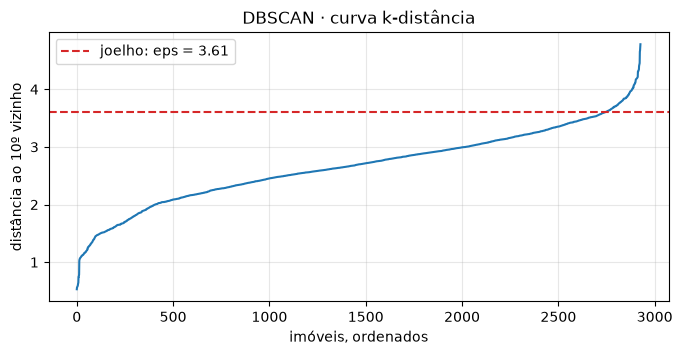

In [7]:
larguras = sorted({round(float(estimate_bandwidth(X, quantile=q, n_samples=1000, random_state=42)), 3)
                   for q in (0.5, 0.4, 0.3, 0.2, 0.15, 0.1, 0.07)}, reverse=True)  # janelas: quantis da distância entre vizinhos

MIN_AMOSTRAS = 10
curva = np.sort(NearestNeighbors(n_neighbors=MIN_AMOSTRAS + 1).fit(X).kneighbors(X)[0][:, -1])  # distância ao 10º vizinho (o 1º é ele mesmo)
eps_joelho = curva[int(cotovelo(np.arange(N), curva))]                                           # joelho da curva
raios = sorted({round(float(np.percentile(curva, p)), 3) for p in range(10, 100, 10)} | {round(float(np.percentile(curva, 95)), 3)},
               reverse=True)                                                                     # percentis da curva, do maior raio ao menor

plt.figure(figsize=(8, 3.5))
plt.plot(curva)
plt.axhline(eps_joelho, color='tab:red', ls='--', label=f'joelho: eps = {eps_joelho:.2f}')
plt.title('DBSCAN · curva k-distância')
plt.xlabel('imóveis, ordenados')
plt.ylabel(f'distância ao {MIN_AMOSTRAS}º vizinho')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [8]:
algoritmos = {  # nome: (valores varridos, função de ajuste, distância da silhueta própria)
    'k-means':             (K, ajustar_kmeans, D_EUC),
    'k-means manhattan':   (K, lambda k: kmedianas(X, k), D_MAN),
    'k-means mahalanobis': (K, ajustar_mahalanobis, D_MAH),
    'k-medoids':           (K, lambda k: kmedoides(D_EUC, k), D_EUC),
    'gmm':                 (K, ajustar_gmm, D_EUC),
    'ward':                (K, ajustar_ward, D_EUC),
    'mean shift':          (larguras, ajustar_mean_shift, D_EUC),
    'dbscan':              (raios, ajustar_dbscan, D_EUC),
}
POR_PARAMETRO = {'mean shift', 'dbscan'}  # nesses, k não é parâmetro: emerge do valor varrido

## 4 · Varredura

In [9]:
linhas = []
for nome, (valores, ajustar, D_propria) in algoritmos.items():
    inicio_algoritmo = time.perf_counter()
    for valor in valores:
        inicio = time.perf_counter()
        rotulos, peso = ajustar(valor)                                  # treina e rotula a base inteira
        validos = rotulos[rotulos >= 0]
        linhas.append({
            'algoritmo': nome,
            'valor': valor,                                             # k, bandwidth ou eps
            'grupos': len(np.unique(validos)),                          # grupos obtidos (sem o ruído)
            'peso': float(peso),
            'silhueta': silhueta(D_propria, rotulos),                   # na régua do próprio algoritmo
            'silhueta_comum': silhueta(D_EUC, rotulos),                 # euclidiana, igual para todos
            'maior_grupo': np.bincount(validos).max() / N if len(validos) else np.nan,  # fatia do maior segmento
            'ruido': 1 - len(validos) / N,                              # fatia sem grupo
            'segundos': time.perf_counter() - inicio,
        })
    print(f'{nome}: {time.perf_counter() - inicio_algoritmo:.0f}s')

varredura = pd.DataFrame(linhas)  # uma linha por configuração treinada

k-means: 4s
k-means manhattan: 11s
k-means mahalanobis: 3s
k-medoids: 4s
gmm: 20s
ward: 3s
mean shift: 145s
dbscan: 1s


In [10]:
def resumir(t):
    t = t.set_index('valor')
    c = cotovelo(t.index, t['peso'])                                    # valor no cotovelo do peso
    m = t['silhueta'].idxmax() if t['silhueta'].notna().any() else None # valor de maior silhueta
    return pd.Series({
        'cotovelo': c, 'melhor': m,
        'k no cotovelo': t.loc[c, 'grupos'] if c is not None else np.nan,
        'silhueta no cotovelo': t.loc[c, 'silhueta'] if c is not None else np.nan,
        'k de maior silhueta': t.loc[m, 'grupos'] if m is not None else np.nan,
        'maior silhueta': t.loc[m, 'silhueta'] if m is not None else np.nan,
        'silhueta comum': t.loc[m, 'silhueta_comum'] if m is not None else np.nan,
        'maior grupo': t.loc[m, 'maior_grupo'] if m is not None else np.nan,
        'ruído': t.loc[m, 'ruido'] if m is not None else np.nan,
        'tempo (s)': t['segundos'].sum(),
    })


resumo = varredura.groupby('algoritmo', sort=False).apply(resumir)  # cotovelo × maior silhueta de cada algoritmo

## 5 · Peso × silhueta de cada algoritmo

Como ler cada painel:
* a **linha tracejada** marca o cotovelo do peso;
* a **estrela** marca a maior silhueta;
* a **faixa verde** é o número de grupos que o negócio opera;
* a **linha pontilhada** é a silhueta mínima.

Quando cotovelo e estrela coincidem, as duas leituras concordam.

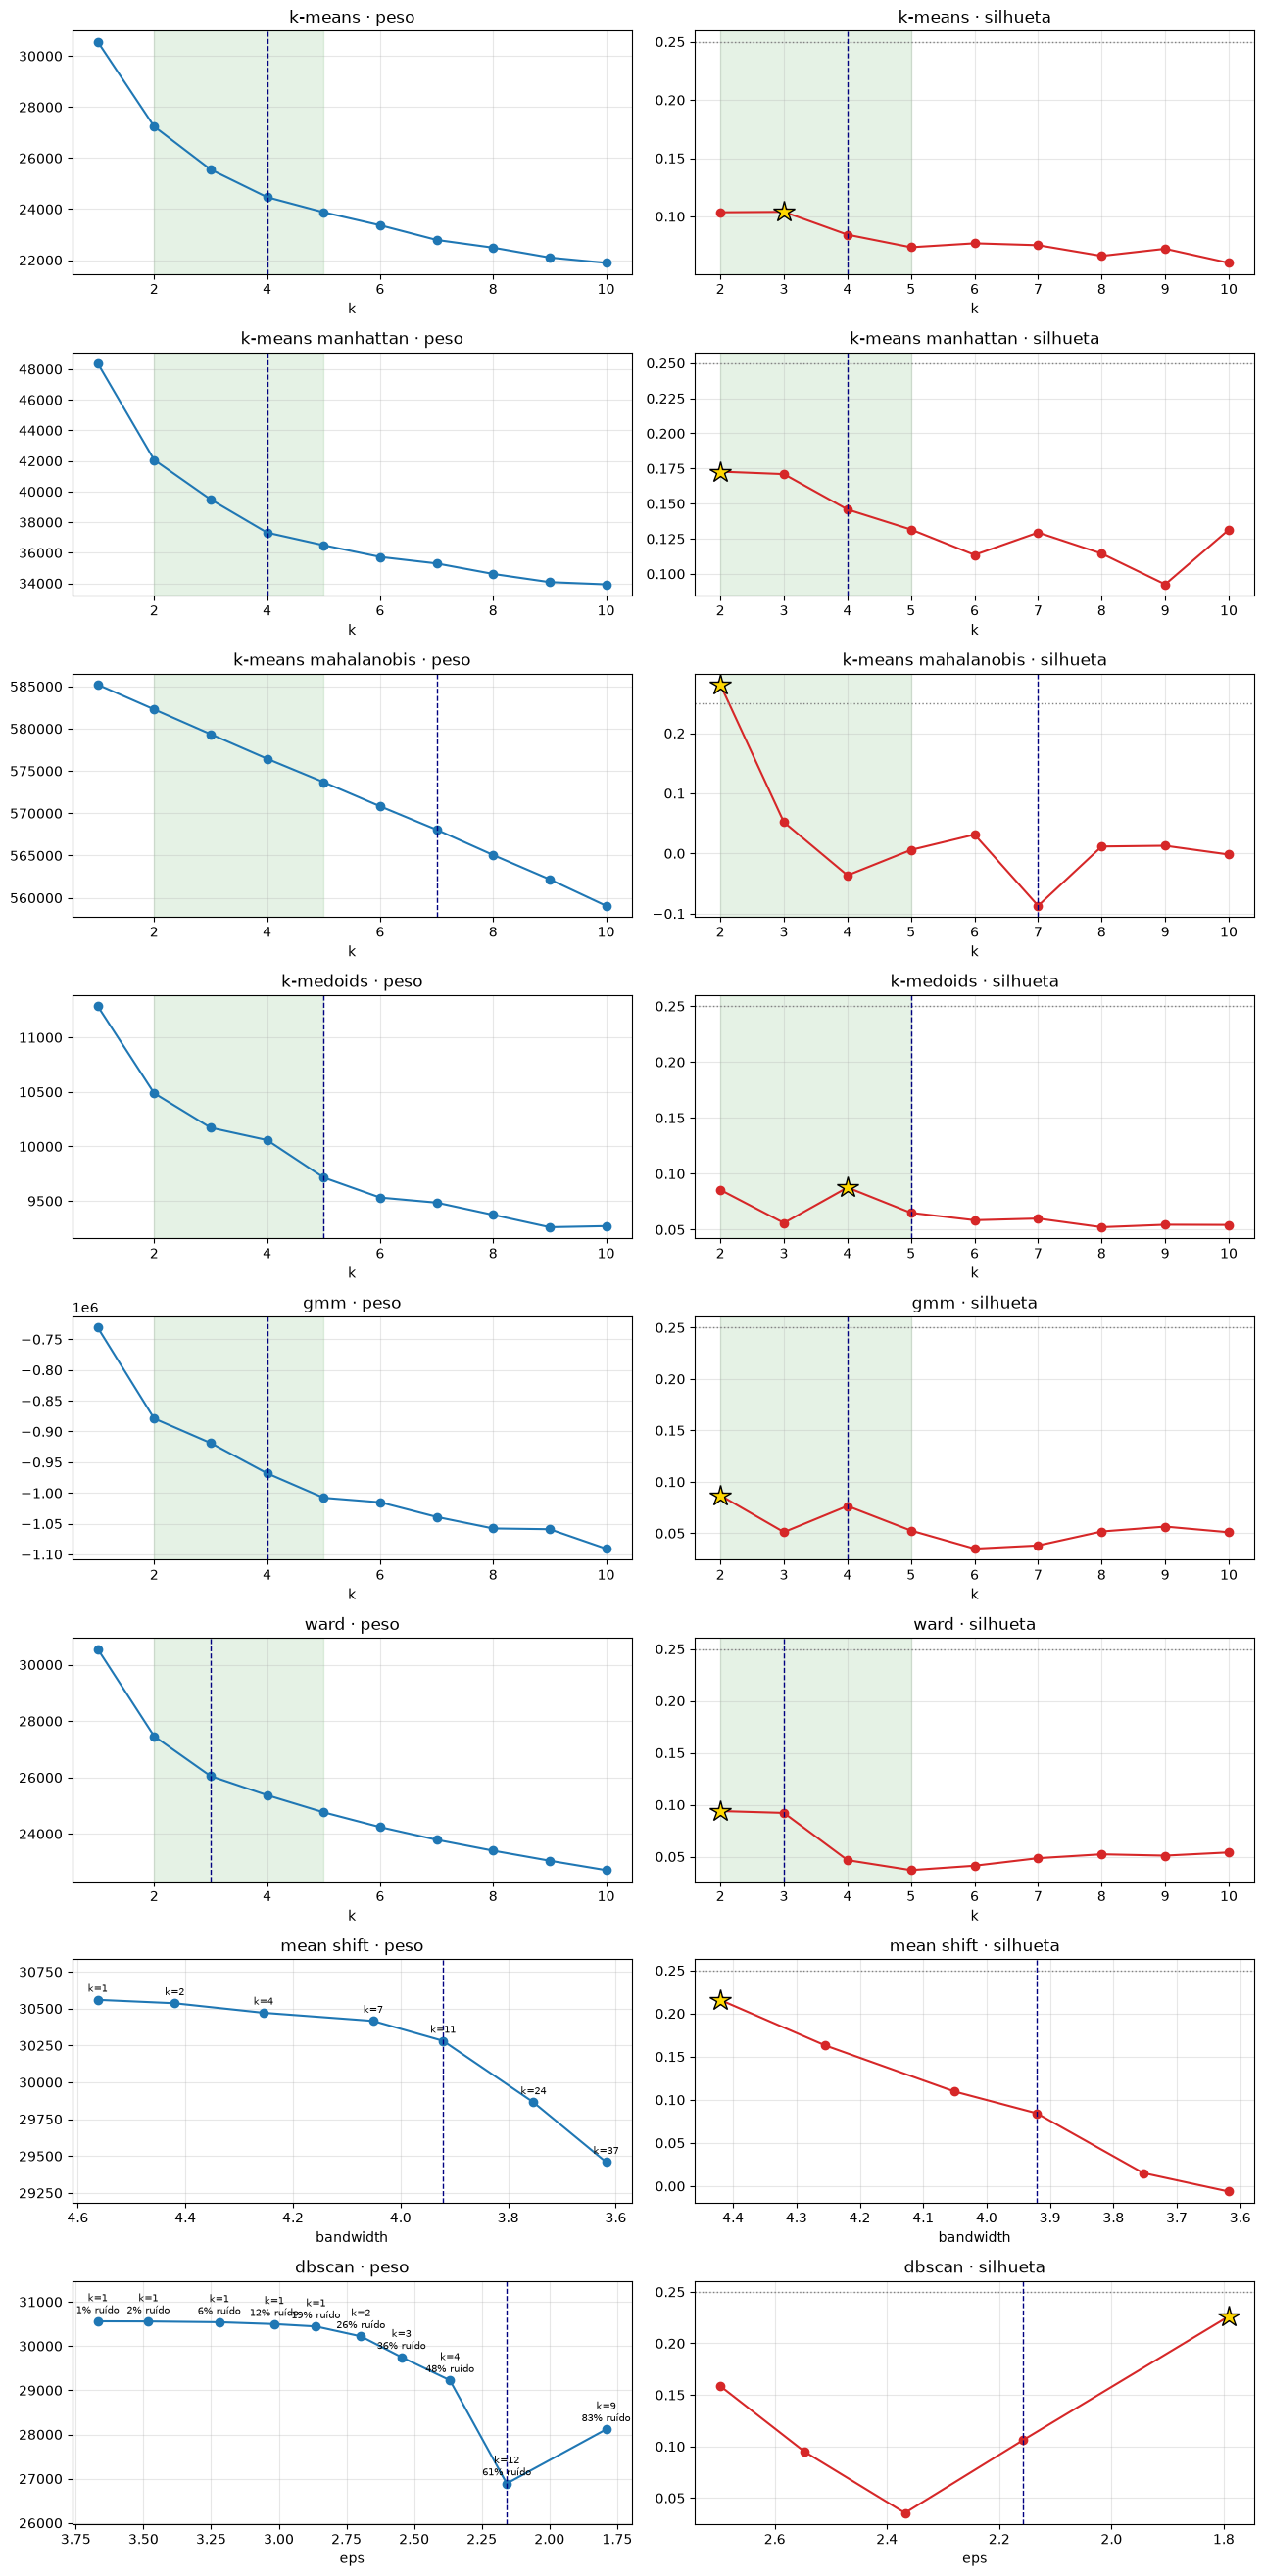

In [11]:
fig, eixos = plt.subplots(len(algoritmos), 2, figsize=(13, 3.3 * len(algoritmos)))

for (ax_peso, ax_sil), (nome, t) in zip(eixos, varredura.groupby('algoritmo', sort=False)):
    c, m = resumo.loc[nome, ['cotovelo', 'melhor']]
    ax_peso.plot(t['valor'], t['peso'], 'o-')                           # o custo que o algoritmo minimiza
    ax_sil.plot(t['valor'], t['silhueta'], 'o-', color='tab:red')       # silhueta na régua do algoritmo
    ax_sil.axhline(SILHUETA_MINIMA, color='gray', ls=':', lw=1)         # silhueta mínima aceita
    if pd.notna(m):
        ax_sil.plot(m, t.set_index('valor').loc[m, 'silhueta'], '*', ms=16, color='gold', mec='black')  # maior silhueta

    for ax in (ax_peso, ax_sil):
        ax.grid(alpha=0.3)
        if pd.notna(c):
            ax.axvline(c, color='navy', ls='--', lw=1)                  # cotovelo do peso
        if nome in POR_PARAMETRO:
            ax.invert_xaxis()                                           # do maior ao menor parâmetro: k cresce para a direita
        else:
            ax.axvspan(*FAIXA, color='green', alpha=0.1)                # faixa que o negócio opera

    if nome in POR_PARAMETRO:                                           # anota o k que cada valor produziu
        for x, y, g, r in zip(t['valor'], t['peso'], t['grupos'], t['ruido']):
            ax_peso.annotate(f'k={g}' + (f'\n{r:.0%} ruído' if r else ''), (x, y),
                             textcoords='offset points', xytext=(0, 6), ha='center', fontsize=7)
        ax_peso.margins(y=0.25)

    rotulo_x = {'mean shift': 'bandwidth', 'dbscan': 'eps'}.get(nome, 'k')
    ax_peso.set(title=f'{nome} · peso', xlabel=rotulo_x)
    ax_sil.set(title=f'{nome} · silhueta', xlabel=rotulo_x)

fig.tight_layout()
plt.show()

## 6 · Comparativo

In [12]:
(resumo.drop(columns=['cotovelo', 'melhor'])
 .style.format(precision=3, na_rep='—')
 .format({'k no cotovelo': '{:.0f}', 'k de maior silhueta': '{:.0f}', 'maior grupo': '{:.1%}',
          'ruído': '{:.1%}', 'tempo (s)': '{:.1f}'}, na_rep='—')
 .highlight_max(subset=['silhueta comum'], color='#d8f3dc'))  # silhueta comum: a que compara algoritmos entre si

,k no cotovelo,silhueta no cotovelo,k de maior silhueta,maior silhueta,silhueta comum,maior grupo,ruído,tempo (s)
algoritmo,,,,,,,,
k-means,4,0.084335,3,0.103953,0.103953,37.4%,0.0%,3.8
k-means manhattan,4,0.145830,2,0.172761,0.097085,57.1%,0.0%,10.9
k-means mahalanobis,7,-0.086961,2,0.280693,0.064341,99.5%,0.0%,3.0
k-medoids,5,0.065076,4,0.087730,0.087730,41.6%,0.0%,4.1
gmm,4,0.076489,2,0.086757,0.086757,53.1%,0.0%,20.3
ward,3,0.092118,2,0.093921,0.093921,66.0%,0.0%,3.3
mean shift,11,0.084431,2,0.215699,0.215699,100.0%,0.0%,145.1
dbscan,12,0.105987,9,0.226227,0.226227,8.0%,82.6%,1.0


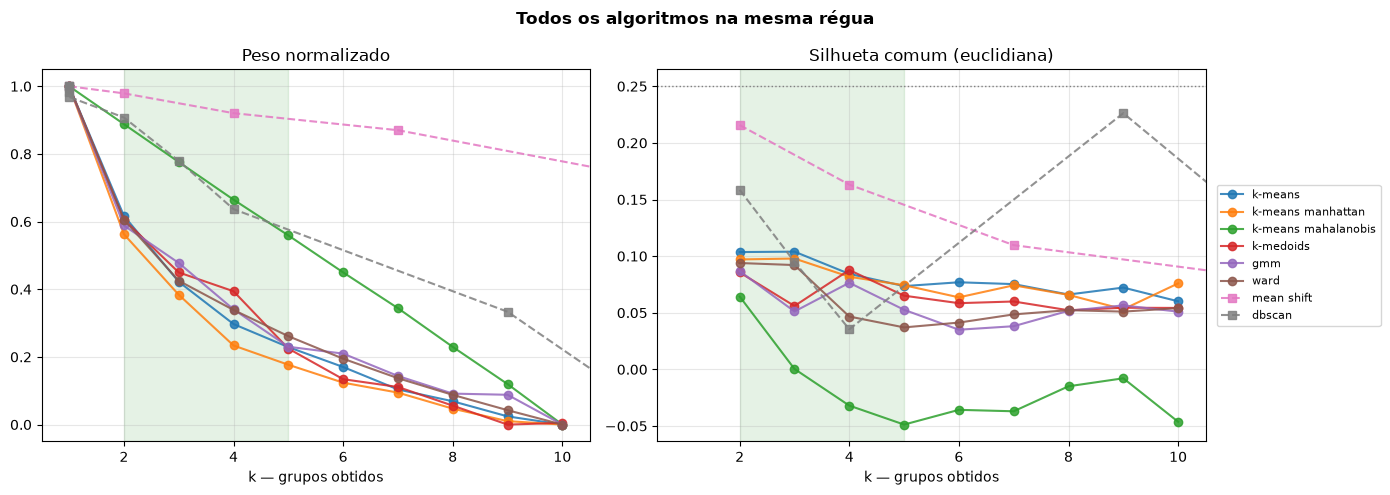

In [13]:
fig, (ax_peso, ax_sil) = plt.subplots(1, 2, figsize=(14, 5))

for nome, t in varredura.groupby('algoritmo', sort=False):
    t = t.sort_values('grupos')
    estilo = 's--' if nome in POR_PARAMETRO else 'o-'
    peso_norm = (t['peso'] - t['peso'].min()) / (t['peso'].max() - t['peso'].min())  # pesos têm unidades diferentes: 1 = maior, 0 = menor
    ax_peso.plot(t['grupos'], peso_norm, estilo, label=nome, alpha=0.85)
    ax_sil.plot(t['grupos'], t['silhueta_comum'], estilo, label=nome, alpha=0.85)

for ax in (ax_peso, ax_sil):
    ax.axvspan(*FAIXA, color='green', alpha=0.1)
    ax.set(xlabel='k — grupos obtidos', xlim=(0.5, K[-1] + 0.5))
    ax.grid(alpha=0.3)
ax_sil.axhline(SILHUETA_MINIMA, color='gray', ls=':', lw=1)
ax_peso.set_title('Peso normalizado')
ax_sil.set_title('Silhueta comum (euclidiana)')
ax_sil.legend(fontsize=8, loc='center left', bbox_to_anchor=(1.01, 0.5))
fig.suptitle('Todos os algoritmos na mesma régua', fontweight='bold')
fig.tight_layout()
plt.show()

## 7 · A escolha

Regra declarada antes de olhar o resultado:
1. *k* dentro da faixa que o negócio opera;
2. ruído até o teto e nenhum grupo com mais de 90% da carteira;
3. entre os que sobram, vence a maior **silhueta comum**. Abaixo da silhueta mínima, o vencedor sai com a ressalva de que a estrutura é fraca.

In [14]:
aprovados = (
    varredura
    .query('@FAIXA[0] <= grupos <= @FAIXA[1]')  # faixa de segmentos do negócio
    .query('ruido <= @RUIDO_MAXIMO')            # teto de imóveis sem grupo
    .query('maior_grupo <= @GRUPO_MAXIMO')      # nenhum grupo dominante
    .dropna(subset=['silhueta_comum'])
    .sort_values('silhueta_comum', ascending=False)
)
print(f'{len(aprovados)} de {len(varredura)} configurações passam na regra. '
      f'Sem nenhuma aprovada: {sorted(set(varredura.algoritmo) - set(aprovados.algoritmo)) or "nenhum"}')

display(aprovados.head(10).style.hide(axis='index').format(precision=3)
        .format({'maior_grupo': '{:.1%}', 'ruido': '{:.1%}', 'peso': '{:,.1f}', 'segundos': '{:.1f}'}))

vencedor = aprovados.iloc[0]
ressalva = '' if vencedor['silhueta_comum'] >= SILHUETA_MINIMA else ' (abaixo da silhueta mínima: estrutura fraca)'
print(f"Vencedor: {vencedor['algoritmo']} com k = {vencedor['grupos']} · silhueta comum {vencedor['silhueta_comum']:.3f}{ressalva}")

21 de 77 configurações passam na regra. Sem nenhuma aprovada: ['dbscan', 'mean shift']


algoritmo,valor,grupos,peso,silhueta,silhueta_comum,maior_grupo,ruido,segundos
k-means,3.000000,3,"25,550.0",0.103953,0.103953,37.4%,0.0%,0.3
k-means,2.000000,2,"27,237.6",0.103591,0.103591,59.8%,0.0%,0.3
k-means manhattan,3.000000,3,"39,482.0",0.170974,0.097876,40.8%,0.0%,1.0
k-means manhattan,2.000000,2,"42,069.0",0.172761,0.097085,57.1%,0.0%,1.1
ward,2.000000,2,"27,463.3",0.093921,0.093921,66.0%,0.0%,0.2
ward,3.000000,3,"26,048.1",0.092118,0.092118,42.8%,0.0%,0.2
k-medoids,4.000000,4,"10,058.5",0.087730,0.087730,41.6%,0.0%,0.5
gmm,2.000000,2,"-878,896.3",0.086757,0.086757,53.1%,0.0%,0.6
k-medoids,2.000000,2,"10,488.2",0.085608,0.085608,50.1%,0.0%,0.5
k-means,4.000000,4,"24,466.8",0.084335,0.084335,35.7%,0.0%,0.3


Vencedor: k-means com k = 3 · silhueta comum 0.104 (abaixo da silhueta mínima: estrutura fraca)


## Como ler o que saiu

* **O peso cai sempre e, sozinho, não escolhe nada.** O cotovelo só diz onde a queda perde fôlego. Se a curva desce quase em linha reta, não há cotovelo de verdade.
* **Silhueta baixa em todos os algoritmos é um resultado.** Em ~200 dimensões, a maioria one-hot, as distâncias se concentram e todo imóvel fica a distâncias parecidas de todos os grupos.
* **Mean Shift e DBSCAN dependem de densidade**, e é a densidade que mais se dilui em alta dimensão. O esperado é um grupo gigante com satélites, ou muito ruído.
* **Mahalanobis amplifica o raro.** Ele dá a uma categoria com poucos imóveis o mesmo peso da área construída.
* **Quando as variantes de centro empatam na régua comum, o desempate é de negócio.** O medoide é um imóvel real, o GMM dá grau de pertencimento e o Ward dá o dendrograma.